# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Rayhan Lutfi Hakim | 5054251043 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score
import warnings

warnings.filterwarnings("ignore")
torch.manual_seed(42)
np.random.seed(42)

In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv("Churn_Modelling.csv")
display(df.head())
print("Jumlah baris dan kolom:", df.shape)
df.info()
display(df.describe())
print(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Jumlah baris dan kolom: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


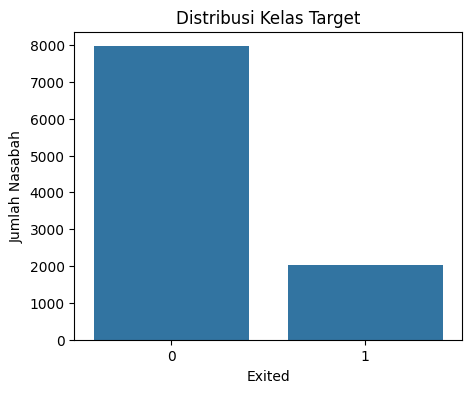

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
counts = df["Exited"].value_counts().sort_index()
plt.figure(figsize=(5, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.xlabel("Exited")
plt.ylabel("Jumlah Nasabah")
plt.title("Distribusi Kelas Target")
plt.show()
print(df["Exited"].value_counts(normalize=True))

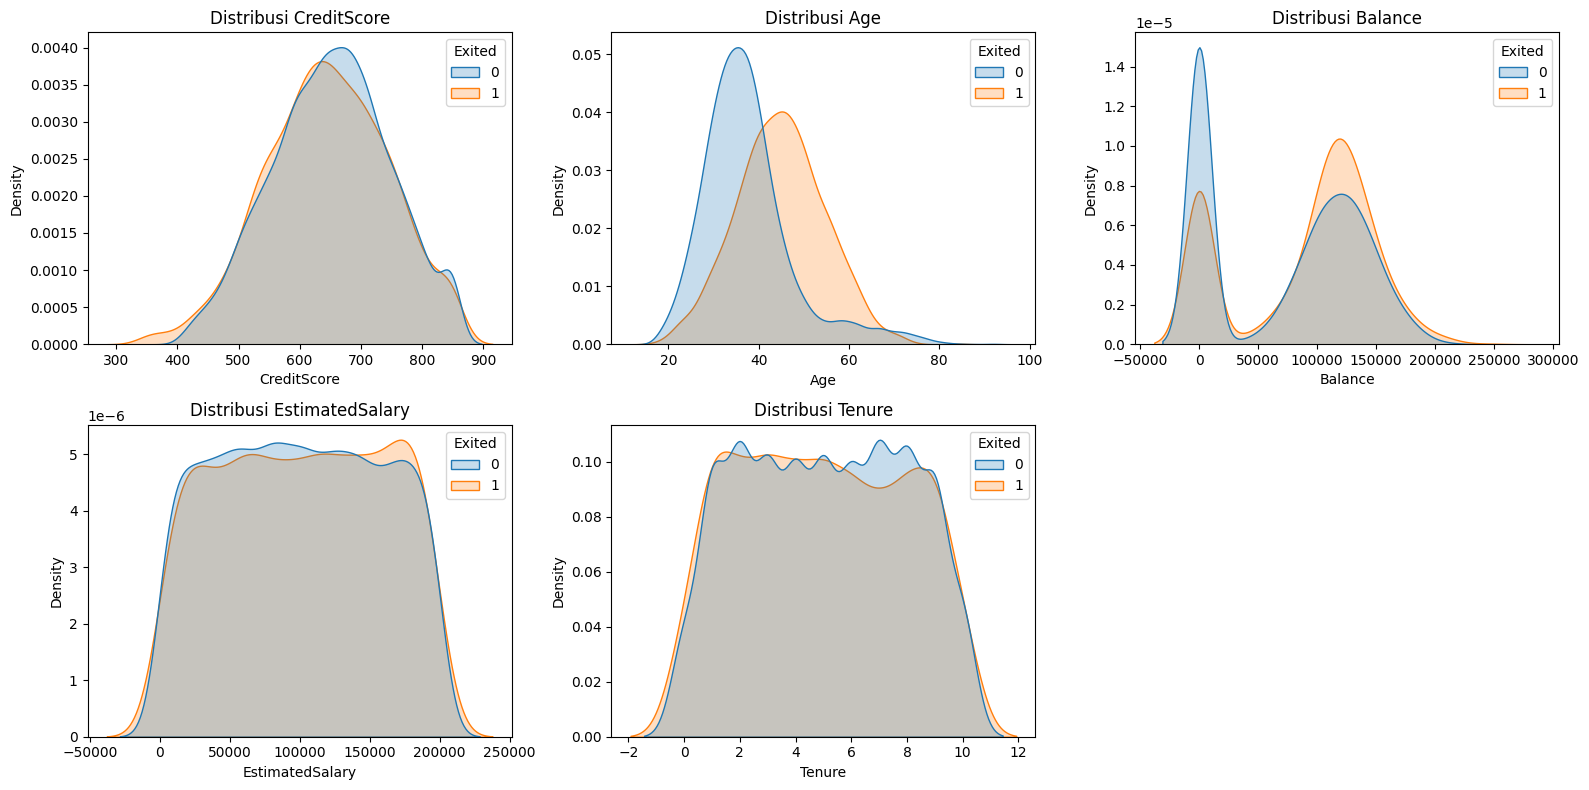

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
num_cols_eda = ["CreditScore", "Age", "Balance", "EstimatedSalary", "Tenure"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols_eda):
    sns.kdeplot(data=df, x=col, hue="Exited", common_norm=False, fill=True, ax=ax)
    ax.set_title(f"Distribusi {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

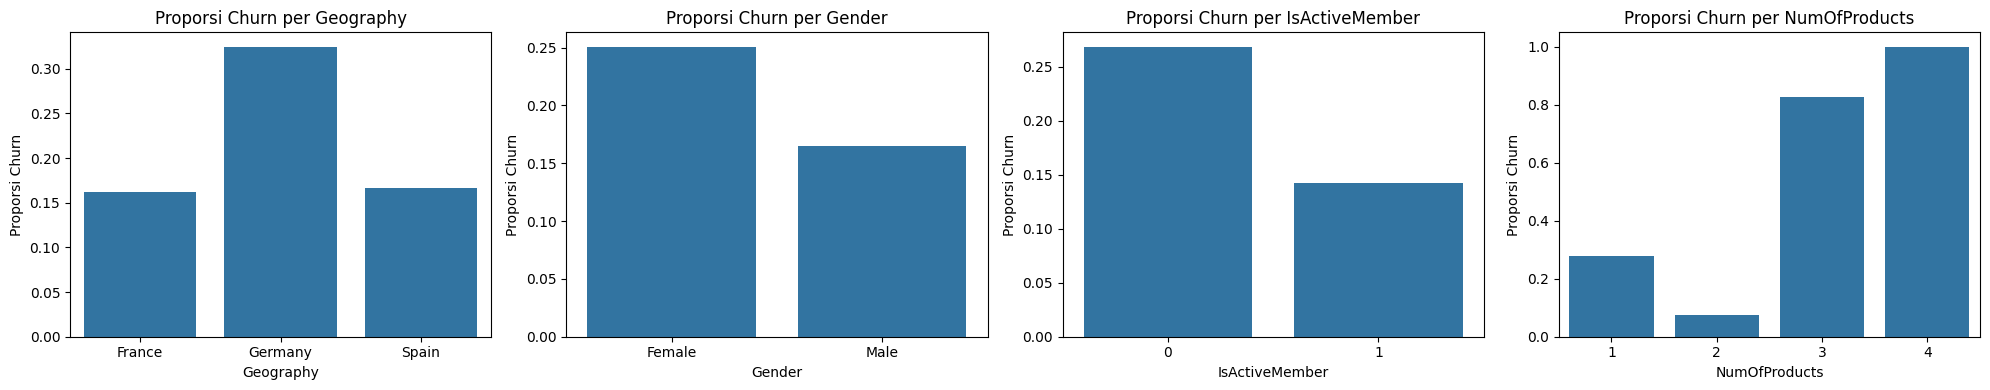

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
cat_cols_eda = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, cat_cols_eda):
    rate = df.groupby(col)["Exited"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f"Proporsi Churn per {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Proporsi Churn")
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [6]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

In [7]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.
X = df.drop(columns="Exited")
y = df["Exited"]
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print(y_train.mean(), y_val.mean(), y_test.mean())

Train: (7000, 10) Validation: (1500, 10) Test: (1500, 10)
0.2037142857142857 0.204 0.20333333333333334


In [8]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()
for d in (X_train, X_val, X_test):
    d["Gender"] = (d["Gender"] == "Male").astype(int)

num_features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
cat_features = ["Geography"]
bin_features = ["Gender", "HasCrCard", "IsActiveMember"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(sparse_output=False), cat_features),
    ("bin", "passthrough", bin_features),
])

X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)
print(X_train_p.shape, X_val_p.shape, X_test_p.shape)

(7000, 12) (1500, 12) (1500, 12)


In [9]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.
def to_tensor(X_arr, y_arr):
    X_t = torch.tensor(np.asarray(X_arr, dtype=np.float32), dtype=torch.float32)
    y_t = torch.tensor(np.asarray(y_arr, dtype=np.float32), dtype=torch.float32).view(-1, 1)
    return X_t, y_t

X_train_t, y_train_t = to_tensor(X_train_p, y_train)
X_val_t, y_val_t = to_tensor(X_val_p, y_val)
X_test_t, y_test_t = to_tensor(X_test_p, y_test)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [10]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_p, y_train)
lr_pred = lr_model.predict(X_test_p)
lr_prob = lr_model.predict_proba(X_test_p)[:, 1]

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [11]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).
class SimpleANN(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)

input_dim = X_train_t.shape[1]
torch.manual_seed(42)
ann_simple = SimpleANN(input_dim)
print(ann_simple)
print("Jumlah parameter:", sum(p.numel() for p in ann_simple.parameters()))

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [12]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.
def evaluate_tensor(model, X_t, y_t, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(X_t)
        loss = criterion(logits, y_t).item()
        preds = (torch.sigmoid(logits) >= 0.5).float()
        acc = (preds == y_t).float().mean().item()
    return loss, acc

def train_model(model, criterion, optimizer, epochs, loader):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            logits = model(xb)
            loss = criterion(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        tr_loss, tr_acc = evaluate_tensor(model, X_train_t, y_train_t, criterion)
        va_loss, va_acc = evaluate_tensor(model, X_val_t, y_val_t, criterion)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch + 1}/{epochs} | train_loss {tr_loss:.4f} | train_acc {tr_acc:.4f} | val_loss {va_loss:.4f} | val_acc {va_acc:.4f}")
    return history

EPOCHS = 100
LEARNING_RATE = 0.001
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(ann_simple.parameters(), lr=LEARNING_RATE)
history_simple = train_model(ann_simple, criterion, optimizer, EPOCHS, train_loader)

Epoch 10/100 | train_loss 0.3647 | train_acc 0.8450 | val_loss 0.3515 | val_acc 0.8507
Epoch 20/100 | train_loss 0.3513 | train_acc 0.8519 | val_loss 0.3361 | val_acc 0.8533
Epoch 30/100 | train_loss 0.3462 | train_acc 0.8560 | val_loss 0.3326 | val_acc 0.8547
Epoch 40/100 | train_loss 0.3431 | train_acc 0.8556 | val_loss 0.3306 | val_acc 0.8593
Epoch 50/100 | train_loss 0.3411 | train_acc 0.8566 | val_loss 0.3283 | val_acc 0.8607
Epoch 60/100 | train_loss 0.3394 | train_acc 0.8567 | val_loss 0.3265 | val_acc 0.8627
Epoch 70/100 | train_loss 0.3382 | train_acc 0.8579 | val_loss 0.3259 | val_acc 0.8633
Epoch 80/100 | train_loss 0.3374 | train_acc 0.8587 | val_loss 0.3247 | val_acc 0.8667
Epoch 90/100 | train_loss 0.3366 | train_acc 0.8599 | val_loss 0.3236 | val_acc 0.8647
Epoch 100/100 | train_loss 0.3359 | train_acc 0.8603 | val_loss 0.3228 | val_acc 0.8667


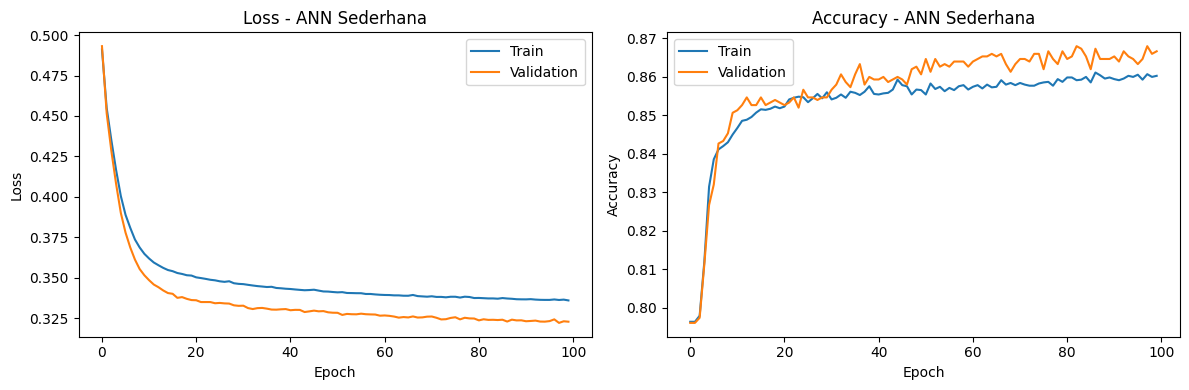

In [13]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title(f"Accuracy - {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_simple, "ANN Sederhana")

In [14]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.
def predict_model(model, X_t):
    model.eval()
    with torch.no_grad():
        logits = model(X_t)
        prob = torch.sigmoid(logits)
        label = (prob >= 0.5).int()
    return prob.numpy().ravel(), label.numpy().ravel()

simple_prob, simple_pred = predict_model(ann_simple, X_test_t)

## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [15]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.
class DeepANN(nn.Module):
    def __init__(self, in_features, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
ann_deep = DeepANN(input_dim)
print(ann_deep)
print("Jumlah parameter:", sum(p.numel() for p in ann_deep.parameters()))

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


Epoch 10/100 | train_loss 0.3478 | train_acc 0.8554 | val_loss 0.3370 | val_acc 0.8553
Epoch 20/100 | train_loss 0.3338 | train_acc 0.8619 | val_loss 0.3265 | val_acc 0.8633
Epoch 30/100 | train_loss 0.3260 | train_acc 0.8663 | val_loss 0.3249 | val_acc 0.8687
Epoch 40/100 | train_loss 0.3218 | train_acc 0.8683 | val_loss 0.3223 | val_acc 0.8727
Epoch 50/100 | train_loss 0.3176 | train_acc 0.8699 | val_loss 0.3237 | val_acc 0.8640
Epoch 60/100 | train_loss 0.3156 | train_acc 0.8697 | val_loss 0.3260 | val_acc 0.8713
Epoch 70/100 | train_loss 0.3112 | train_acc 0.8723 | val_loss 0.3241 | val_acc 0.8700
Epoch 80/100 | train_loss 0.3074 | train_acc 0.8733 | val_loss 0.3219 | val_acc 0.8607
Epoch 90/100 | train_loss 0.3062 | train_acc 0.8749 | val_loss 0.3290 | val_acc 0.8627
Epoch 100/100 | train_loss 0.3018 | train_acc 0.8753 | val_loss 0.3260 | val_acc 0.8653


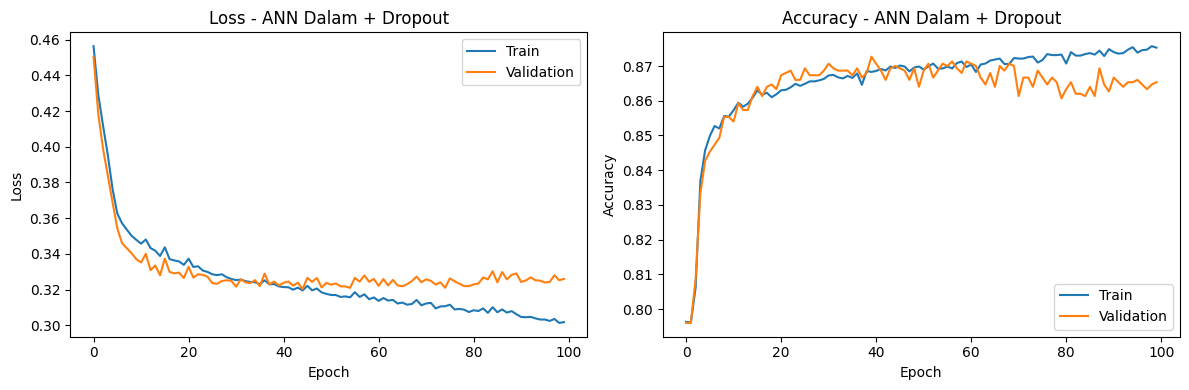

In [16]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(ann_deep.parameters(), lr=LEARNING_RATE)
history_deep = train_model(ann_deep, criterion, optimizer, EPOCHS, train_loader)
plot_history(history_deep, "ANN Dalam + Dropout")

In [17]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
deep_prob, deep_pred = predict_model(ann_deep, X_test_t)

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [18]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).
val_f1_simple = f1_score(y_val, predict_model(ann_simple, X_val_t)[1])
val_f1_deep = f1_score(y_val, predict_model(ann_deep, X_val_t)[1])
print("F1 validation ANN sederhana:", round(val_f1_simple, 4))
print("F1 validation ANN dalam + Dropout:", round(val_f1_deep, 4))

torch.manual_seed(42)
if val_f1_deep >= val_f1_simple:
    ann_weighted = DeepANN(input_dim)
    print("Arsitektur yang dipakai: ANN dalam + Dropout")
else:
    ann_weighted = SimpleANN(input_dim)
    print("Arsitektur yang dipakai: ANN sederhana")

pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print("pos_weight:", round(pos_weight, 4))

criterion_w = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]))
optimizer_w = torch.optim.Adam(ann_weighted.parameters(), lr=LEARNING_RATE)
history_weighted = train_model(ann_weighted, criterion_w, optimizer_w, EPOCHS, train_loader)

F1 validation ANN sederhana: 0.5968
F1 validation ANN dalam + Dropout: 0.5878
Arsitektur yang dipakai: ANN sederhana
pos_weight: 3.9088
Epoch 10/100 | train_loss 0.7842 | train_acc 0.7583 | val_loss 0.7435 | val_acc 0.7633
Epoch 20/100 | train_loss 0.7619 | train_acc 0.7730 | val_loss 0.7168 | val_acc 0.7773
Epoch 30/100 | train_loss 0.7532 | train_acc 0.7746 | val_loss 0.7115 | val_acc 0.7793
Epoch 40/100 | train_loss 0.7454 | train_acc 0.7744 | val_loss 0.7082 | val_acc 0.7720
Epoch 50/100 | train_loss 0.7365 | train_acc 0.7823 | val_loss 0.7013 | val_acc 0.7847
Epoch 60/100 | train_loss 0.7287 | train_acc 0.7937 | val_loss 0.6948 | val_acc 0.7927
Epoch 70/100 | train_loss 0.7240 | train_acc 0.7956 | val_loss 0.6921 | val_acc 0.7947
Epoch 80/100 | train_loss 0.7214 | train_acc 0.7950 | val_loss 0.6914 | val_acc 0.7940
Epoch 90/100 | train_loss 0.7193 | train_acc 0.7959 | val_loss 0.6899 | val_acc 0.7933
Epoch 100/100 | train_loss 0.7177 | train_acc 0.7989 | val_loss 0.6894 | val_acc 

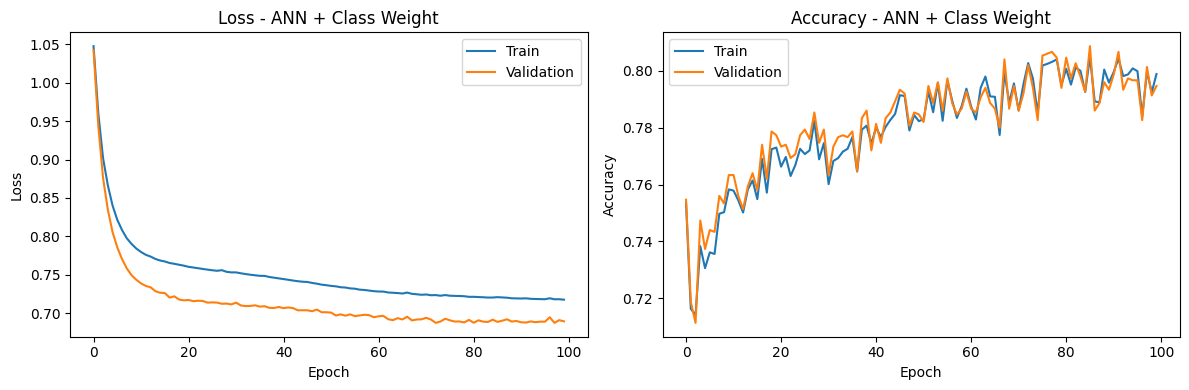

In [19]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
plot_history(history_weighted, "ANN + Class Weight")
weighted_prob, weighted_pred = predict_model(ann_weighted, X_test_t)

# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
models_eval = {
    "Logistic Regression": (lr_pred, lr_prob),
    "ANN Sederhana": (simple_pred, simple_prob),
    "ANN Dalam + Dropout": (deep_pred, deep_prob),
    "ANN + Class Weight": (weighted_pred, weighted_prob),
}

rows = []
for name, (pred, prob) in models_eval.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
    })
results_df = pd.DataFrame(rows).set_index("Model").round(4)
display(results_df)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092
ANN Sederhana,0.8673,0.7650,0.5016,0.6059
ANN Dalam + Dropout,0.8647,0.7684,0.4787,0.5899
ANN + Class Weight,0.7900,0.4896,0.7705,0.5987


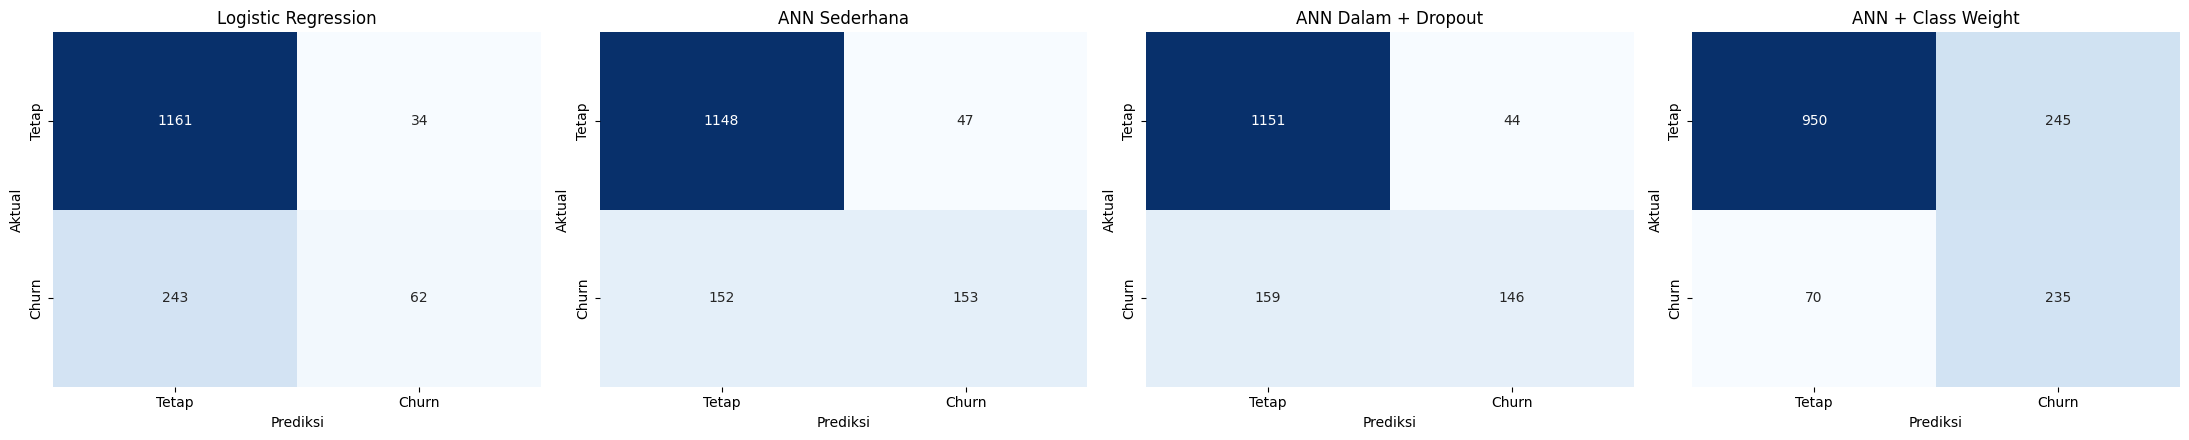

In [21]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, (name, (pred, prob)) in zip(axes, models_eval.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["Tetap", "Churn"], yticklabels=["Tetap", "Churn"])
    ax.set_title(name)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

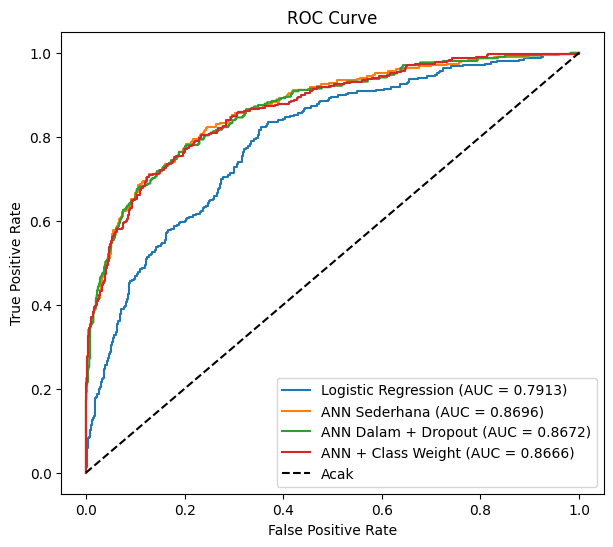

In [22]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.
plt.figure(figsize=(7, 6))
for name, (pred, prob) in models_eval.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

Melihat dari hasil curve, tidak ada yang menagalami overfit ataupun underfit kecuali logreg yang mengalami overfitting. Melihat dari evaluasi model dengan 4 hal (akurasi, f1, recall, precision) ANN + class weight memang paling rendah dalam hal akurasi, namun melihat dari 3 hal lainnya logisitc regression yang paling tidak seimbang. ANN Dalam + Dropout memiliki ROC-AUC tertinggi 0.8588, sedangkan ANN + Class Weight unggul untuk deteksi churn dengan Recall 0.7344 dan F1-Score tertinggi 0.5944. Penambahan arsitektur dari 1 hidden layer (16 neuron, 225 parameter) menjadi 3 hidden layer (64 → 32 → 16 neuron, 3.457 parameter) memungkinkan model menangkap pola non-linear yang lebih kompleks pada data nasabah. Dropout bekerja dengan cara mematikan (menonaktifkan) sejumlah neuron secara acak selama proses pelatihan (training) pada jaringan saraf tiruan (neural network) sehingga model dipaksa untuk belajar model umum bukan bergantung pada satu jalur atau kombinasi fitur tertentu saja. Memberikan penalti 4 kali lliapt terhadap kesalah churn membuat recall melonjak karena tidak mengulangi kesalahan yang sama. Namun dibalik itu precision dikorbankan akibat membuat model lebih agresif sehingga accuracy turun karena meningkatnya jumlah false positive. 

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

Model non-linear (ANN Sederhana) jauh mengungguli baseline linear (Logistic Regression) dengan F1-Score 0.6059 vs 0.3092 dan Accuracy 86,73% vs 81,53%. Penambahan kedalaman + Dropout (ANN Dalam + Dropout) tidak memberikan peningkatan (F1-Score 0.5899). Penggunaan pos_weight (ANN + Class Weight) berhasil meningkatkan Recall dari 0.5016 menjadi 0.7705. Karena dataset didominasi kelas non-churn (~80%), lakukan threshold tuning (menggeser ambang probabilitas dari 0.5 berdasarkan kurva Precision-Recall) atau coba teknik oversampling seperti SMOTE.